<a href="https://colab.research.google.com/github/EnesKok20/cepte-vet/blob/main/notebooks/05_ilk_egitim.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

!pip -q install ultralytics
!nvidia-smi --query-gpu=name --format=csv

ANA = '/content/drive/MyDrive/436543_Enes_kok/cepte-veterinerlik'
!mkdir -p /content/data && cp "{ANA}/hazir/cattle_cls.zip" /content/data/
!cd /content/data && unzip -q -o cattle_cls.zip
!find /content/data/cattle_cls -type f | cut -d/ -f5,6 | sort | uniq -c

Mounted at /content/drive
name
Tesla T4
    276 test/healthy
    183 test/lumpy
   1285 train/healthy
    852 train/lumpy
    276 val/healthy
    182 val/lumpy


In [2]:
from ultralytics import YOLO

model = YOLO('yolo11n-cls.pt')
sonuc = model.train(
    data='/content/data/cattle_cls',
    epochs=30,
    imgsz=224,
    batch=32,
    patience=10,
    seed=42,
    project=f'{ANA}/runs',
    name='baseline_yolo11n',
    exist_ok=True,
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.198 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data/cattle_cls, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=

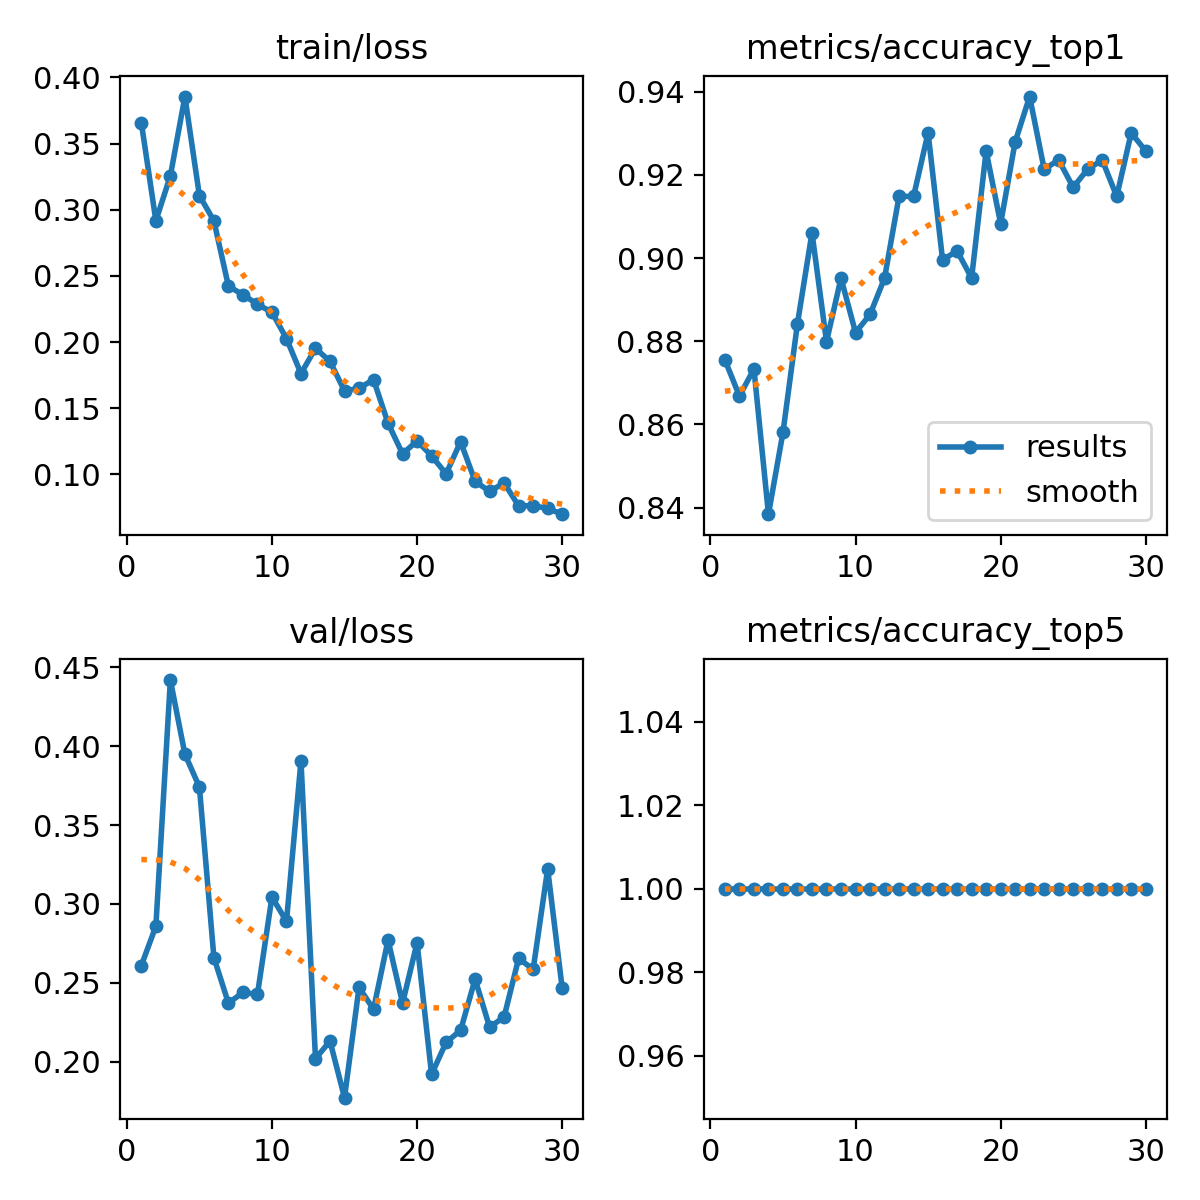

In [3]:
from IPython.display import Image as GosterResim, display
display(GosterResim(f'{ANA}/runs/baseline_yolo11n/results.png', width=900))


              precision    recall  f1-score   support

     healthy      0.921     0.935     0.928       276
       lumpy      0.899     0.880     0.890       183

    accuracy                          0.913       459
   macro avg      0.910     0.907     0.909       459
weighted avg      0.913     0.913     0.913       459



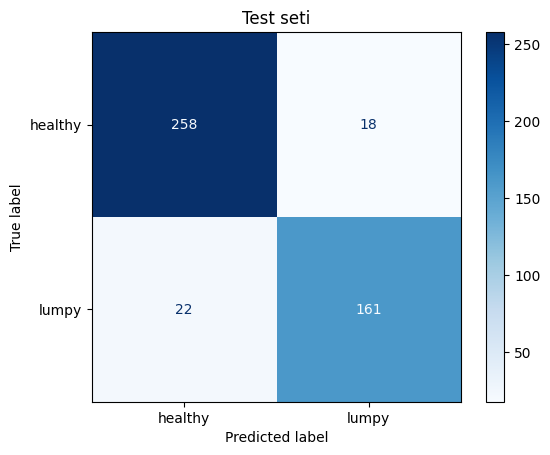

In [4]:
import glob, os
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

en_iyi = YOLO(f'{ANA}/runs/baseline_yolo11n/weights/best.pt')
yollar = sorted(glob.glob('/content/data/cattle_cls/test/*/*'))
gercek = [os.path.basename(os.path.dirname(y)) for y in yollar]

tahmin = []
for i in range(0, len(yollar), 64):
    for r in en_iyi.predict(yollar[i:i + 64], imgsz=224, verbose=False):
        tahmin.append(r.names[r.probs.top1])

print(classification_report(gercek, tahmin, digits=3))
ConfusionMatrixDisplay(confusion_matrix(gercek, tahmin, labels=['healthy', 'lumpy']),
                       display_labels=['healthy', 'lumpy']).plot(cmap='Blues')
plt.title('Test seti'); plt.show()

Yanlış tahmin: 40 / 459


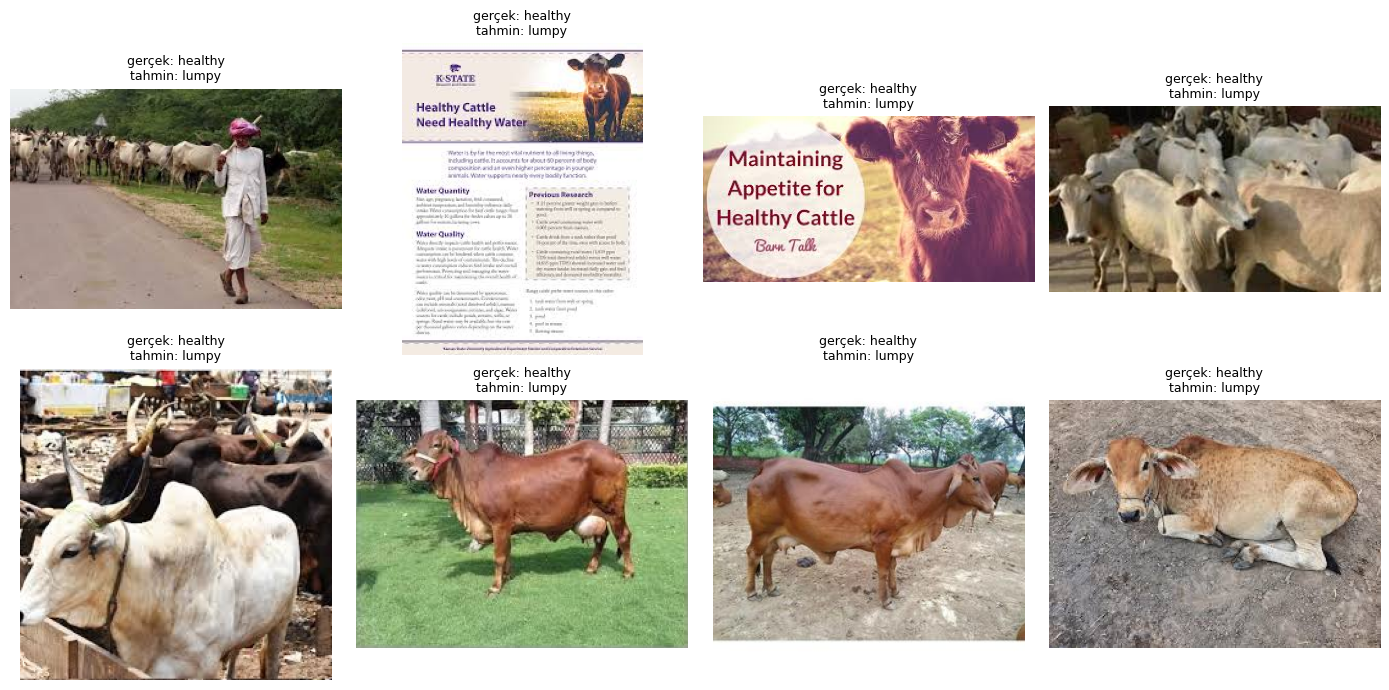

In [5]:
from PIL import Image
yanlis = [(y, g, t) for y, g, t in zip(yollar, gercek, tahmin) if g != t]
print('Yanlış tahmin:', len(yanlis), '/', len(yollar))

n = min(8, len(yanlis))
if n:
    fig, eks = plt.subplots(2, 4, figsize=(14, 7))
    for ax in eks.flat: ax.axis('off')
    for ax, (y, g, t) in zip(eks.flat, yanlis[:n]):
        ax.imshow(Image.open(y).convert('RGB'))
        ax.set_title(f'gerçek: {g}\ntahmin: {t}', fontsize=9)
    plt.tight_layout(); plt.show()

Kaçırılan hasta: 22


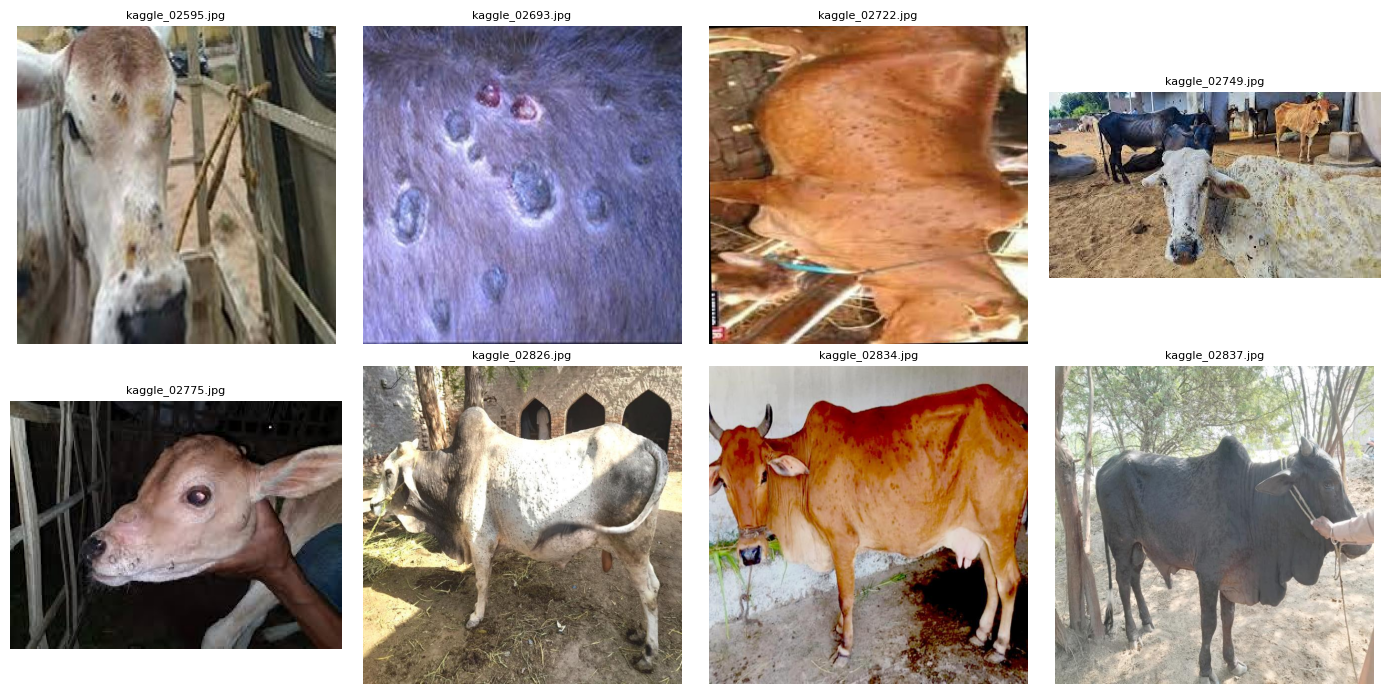

In [6]:
kacan = [(y, g, t) for y, g, t in yanlis if g == 'lumpy']
print('Kaçırılan hasta:', len(kacan))
fig, eks = plt.subplots(2, 4, figsize=(14, 7))
for ax in eks.flat: ax.axis('off')
for ax, (y, g, t) in zip(eks.flat, kacan[:8]):
    ax.imshow(Image.open(y).convert('RGB'))
    ax.set_title(os.path.basename(y), fontsize=8)
plt.tight_layout(); plt.show()